In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    RocCurveDisplay,
    ConfusionMatrixDisplay,
)

import pickle

In [ ]:
df = pd.read_csv("data/processed/HR_capstone_dataset.csv")

# Hypothesis testing

## Using Chi square test for independence

### Null and alternate hypotheses

H0: Having a work accident is independent of employee exit

Ha: Having a work accident is not independent of employee exit

In [ ]:
obs = np.array(df.groupby("Work_accident")["left"].value_counts()).reshape(2, 2)
dx = pd.DataFrame(
    data=obs, index=["no work accident", "work accident"], columns=["not left", "left"]
)
dx

,not left,left
no work accident,8255,1886
work accident,1745,105


In [38]:
result = stats.contingency.chi2_contingency(obs, correction=False)

print(f"Chi2 statistic: {result.statistic}\nP value: {result.pvalue}")

Chi2 statistic: 188.66987572389968
P value: 6.204026915138356e-43


Pvalue << 0.05, thus we reject the null hypothesis

Therefore Having a work accident is not independent of employee exit

---

# Modeling workflow and model selection process

* Split the data into train/validation/test sets (60/20/20)
* Fit models and tune hyperparameters on the training set
* Perform final model selection on the validation set
* Assess the champion model's performance on the test set


## Data Split

In [ ]:
y = df["left"]
X = df.drop("left", axis=1)
X.shape, y.shape

((11991, 9), (11991,))

## Feature Engineering

In [ ]:
# Binning Satisfaction level
X["satisfaction_binned"] = pd.cut(
    X["satisfaction_level"],
    bins=[0, 0.1, 0.35, 0.45, 0.7, 0.9, 1.0],
    labels=[0, 1, 2, 3, 4, 5],
)

In [ ]:
X["last_evaluation_binned"] = pd.cut(
    X["last_evaluation"],
    bins=[0, 0.45, 0.60, 0.75, 0.95, 1.0],
    labels=[0, 1, 2, 3, 4],
)

In [ ]:
X["average_montly_hours_binned"] = pd.cut(
    X["average_montly_hours"],
    bins=[0, 125, 165, 225, 290, np.inf],
    labels=[0, 1, 2, 3, 4],
)

In [ ]:
safe_mask = (X.Department == "management") | (X.Department == "RandD")
X["Department_safe"] = safe_mask.astype(int)


In [ ]:
X["salary_encoded"] = (
    X["salary"].replace({"low": 0, "medium": 1, "high": 2}).astype(int)
)

C:\Users\Sarvamm\AppData\Local\Temp\ipykernel_7132\446782949.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X['salary_encoded'] = X['salary'].replace({


In [ ]:
X = X.drop(
    columns=[
        "satisfaction_level",
        "last_evaluation",
        "average_montly_hours",
        "Department",
        "salary",
    ]
)

In [98]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11991 entries, 0 to 11990
Data columns (total 9 columns):
 #   Column                       Non-Null Count  Dtype   
---  ------                       --------------  -----   
 0   number_project               11991 non-null  int64   
 1   time_spend_company           11991 non-null  int64   
 2   Work_accident                11991 non-null  int64   
 3   promotion_last_5years        11991 non-null  int64   
 4   satisfaction_binned          11991 non-null  category
 5   last_evaluation_binned       11991 non-null  category
 6   average_montly_hours_binned  11991 non-null  category
 7   Department_safe              11991 non-null  int64   
 8   salary_encoded               11991 non-null  int64   
dtypes: category(3), int64(6)
memory usage: 598.0 KB


In [99]:
X_tr, X_test, y_tr, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=0
)

In [100]:
X_tr.shape, X_test.shape, y_tr.shape, y_test.shape

((9592, 9), (2399, 9), (9592,), (2399,))

In [101]:
X_train, X_val, y_train, y_val = train_test_split(
    X_tr, y_tr, test_size=0.2, stratify=y_tr, random_state=0
)

In [102]:
X_train.shape, X_val.shape, y_train.shape, y_val.shape

((7673, 9), (1919, 9), (7673,), (1919,))

Random Forest Model

In [ ]:
rf = RandomForestClassifier(random_state=0, n_jobs=-1)

cv_params = {
    "n_estimators": [10, 100, 500],
    "max_depth": [2, 5, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [4, "sqrt", "log2"],
}

scoring = ["accuracy", "precision", "recall", "f1"]

grid_search = GridSearchCV(
    rf, cv_params, cv=5, scoring=scoring, refit="recall", n_jobs=-1
)

In [148]:
%%time
grid_search.fit(X_train, y_train)

CPU times: total: 8.2 s
Wall time: 2min 19s


,estimator,RandomForestC...andom_state=0)
,param_grid,"{'max_depth': [2, 5, ...], 'max_features': [4, 'sqrt', ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,scoring,"['accuracy', 'precision', ...]"
,n_jobs,-1
,refit,'recall'
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,500


In [ ]:
print(classification_report(y_true=y_val, y_pred=grid_search.predict(X_val)))

              precision    recall  f1-score   support

           0       0.98      0.99      0.99      1600
           1       0.97      0.92      0.94       319

    accuracy                           0.98      1919
   macro avg       0.98      0.96      0.97      1919
weighted avg       0.98      0.98      0.98      1919



Through subsequent iterations of grid search, the following parameters were found to be most optimal.

While no performance uplift was observed, the model runs much faster now.

In [ ]:
best_cv_params = {
    "n_estimators": [175],
    "max_depth": [11],
    "min_samples_split": [3],
    "min_samples_leaf": [1],
    "max_features": [6],
}

In [ ]:
rf_best = GridSearchCV(
    rf, best_cv_params, cv=5, scoring=scoring, refit="recall", n_jobs=-1
)

Pro tip: Use n_jobs = -1 to utilise all cpu cores and train much faster

In [151]:
%%time
rf_best.fit(X_train, y_train)

CPU times: total: 1.03 s
Wall time: 1.23 s


,estimator,RandomForestC...andom_state=0)
,param_grid,"{'max_depth': [11], 'max_features': [6], 'min_samples_leaf': [1], 'min_samples_split': [3], ...}"
,scoring,"['accuracy', 'precision', ...]"
,n_jobs,-1
,refit,'recall'
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,175


In [152]:
print(classification_report(y_true=y_val, y_pred=rf_best.predict(X_val)))

              precision    recall  f1-score   support

           0       0.98      0.99      0.99      1600
           1       0.97      0.92      0.94       319

    accuracy                           0.98      1919
   macro avg       0.98      0.96      0.97      1919
weighted avg       0.98      0.98      0.98      1919



In [ ]:
rf_pred = rf_best.predict(X_val)

score_table = pd.DataFrame(
    data={
        "precision": precision_score(y_val, rf_pred),
        "recall": recall_score(y_val, rf_pred),
        "f1": f1_score(y_val, rf_pred),
        "accuracy": accuracy_score(y_val, rf_pred),
    },
    index=["RandomForest"],
)

In [230]:
def append_model_score(model, name):
    global score_table
    model_pred = model.predict(X_val)
    model_row = pd.DataFrame(
        data={
            "precision": precision_score(y_val, model_pred),
            "recall": recall_score(y_val, model_pred),
            "f1": f1_score(y_val, model_pred),
            "accuracy": accuracy_score(y_val, model_pred),
        },
        index=[name],
    )

    score_table = pd.concat([score_table, model_row], axis=0)

---

XGBoost Classifier

In [ ]:
xg = XGBClassifier(objective="binary:logistic", random_state=0, n_jobs=-1)

cv_params = {
    "max_depth": [4, 8, 12],
    "min_child_weight": [3, 5],
    "learning_rate": [0.01, 0.1],
    "n_estimators": [100, 200, 300],
}

scoring = ["accuracy", "precision", "recall", "f1"]

xg_grid_search = GridSearchCV(xg, cv_params, scoring=scoring, refit="recall", n_jobs=-1)

In [155]:
%%time
xg_grid_search.fit(X_train, y_train)

CPU times: total: 2.92 s
Wall time: 10.9 s


,estimator,"XGBClassifier...ree=None, ...)"
,param_grid,"{'learning_rate': [0.01, 0.1], 'max_depth': [4, 8, ...], 'min_child_weight': [3, 5], 'n_estimators': [100, 200, ...]}"
,scoring,"['accuracy', 'precision', ...]"
,n_jobs,-1
,refit,'recall'
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'binary:logistic'


A few grid searches later..

In [240]:
best_cv_params = {
    "max_depth": [5],
    "min_child_weight": [2],
    "learning_rate": [0.18],
    "n_estimators": [215],
}

xg_best = GridSearchCV(xg, best_cv_params, scoring=scoring, refit="recall", n_jobs=-1)

In [241]:
%%time
xg_best.fit(X_train, y_train)

CPU times: total: 1.38 s
Wall time: 3.01 s


,estimator,"XGBClassifier...ree=None, ...)"
,param_grid,"{'learning_rate': [0.18], 'max_depth': [5], 'min_child_weight': [2], 'n_estimators': [215]}"
,scoring,"['accuracy', 'precision', ...]"
,n_jobs,-1
,refit,'recall'
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'binary:logistic'


In [243]:
append_model_score(xg_best, "XGBoost")

---
Logistic Regression

In [ ]:
lr = LogisticRegression(random_state=0, n_jobs=-1)

cv_params = {
    "solver": ["saga"],
    "penalty": ["elasticnet"],
    "C": np.logspace(-4, 4, 9),
    "l1_ratio": [0.2, 0.5, 0.8],  # Required for elasticnet
}


scoring = ["accuracy", "precision", "recall", "f1"]

lr_grid_search = GridSearchCV(lr, cv_params, scoring=scoring, refit="recall", n_jobs=-1)

In [198]:
%%time
lr_grid_search.fit(X_train, y_train)

CPU times: total: 578 ms
Wall time: 6.46 s


,estimator,LogisticRegre...andom_state=0)
,param_grid,"{'C': array([1.e-04... 1.e+04]), 'l1_ratio': [0.2, 0.5, ...], 'penalty': ['elasticnet'], 'solver': ['saga']}"
,scoring,"['accuracy', 'precision', ...]"
,n_jobs,-1
,refit,'recall'
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'elasticnet'


In [ ]:
append_model_score(lr_grid_search, "LogisticRegression")

---

Decision tree 

In [ ]:
dt = DecisionTreeClassifier(random_state=0)

best_params = {
    "criterion": "entropy",
    "max_depth": 7,
    "max_features": None,
    "min_samples_leaf": 1,
    "min_samples_split": 2,
}

scoring = ["accuracy", "precision", "recall", "f1"]

dt_grid_search = GridSearchCV(dt, cv_params, scoring=scoring, refit="recall", n_jobs=-1)

In [223]:
%%time
dt_grid_search.fit(X_train, y_train)

CPU times: total: 156 ms
Wall time: 225 ms


,estimator,DecisionTreeC...andom_state=0)
,param_grid,"{'criterion': ['entropy'], 'max_depth': [6, 7, ...], 'max_features': [None], 'min_samples_leaf': [1], ...}"
,scoring,"['accuracy', 'precision', ...]"
,n_jobs,-1
,refit,'recall'
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'entropy'


In [224]:
dt_grid_search.best_score_

np.float64(0.9152292728114869)

In [ ]:
append_model_score(dt_grid_search, "DecisionTreeClassifier")

---
# Model Selection

In [ ]:
score_table.sort_values("f1", ascending=False)

,precision,recall,f1,accuracy
RandomForest,0.966997,0.918495,0.942122,0.981240
XGBoost,0.957516,0.918495,0.937600,0.979677
DecisionTreeClassifier,0.930380,0.921630,0.925984,0.975508
LogisticRegression,0.450704,0.200627,0.277657,0.826472


Model selected = RandomForestClassifier

## Testing on unseen data

In [ ]:
model_pred = rf_best.predict(X_test)

print(classification_report(y_true=y_test, y_pred=model_pred))

              precision    recall  f1-score   support

           0       0.98      0.99      0.99      2001
           1       0.96      0.89      0.93       398

    accuracy                           0.98      2399
   macro avg       0.97      0.94      0.96      2399
weighted avg       0.98      0.98      0.98      2399



Training on full data

In [ ]:
best_params = {
    "criterion": "entropy",
    "random_state": 0,
    "class_weight": "balanced",
    "n_estimators": 175,
    "max_depth": 11,
    "min_samples_split": 3,
    "min_samples_leaf": 1,
    "max_features": 6,
}

model = RandomForestClassifier(**best_params)

In [333]:
model.fit(X_tr, y_tr)

,n_estimators,175
,criterion,'entropy'
,max_depth,11
,min_samples_split,3
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,6
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [334]:
model_pred = model.predict(X_test)

In [335]:
print(classification_report(y_true=y_test, y_pred=model_pred))

              precision    recall  f1-score   support

           0       0.98      0.99      0.99      2001
           1       0.96      0.90      0.93       398

    accuracy                           0.98      2399
   macro avg       0.97      0.95      0.96      2399
weighted avg       0.98      0.98      0.98      2399



Model improved very slightly when validation data was included in training

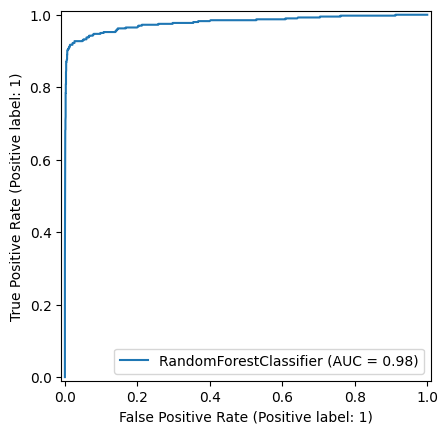

In [336]:
RocCurveDisplay.from_estimator(model, X_test, y_test)

plt.show()

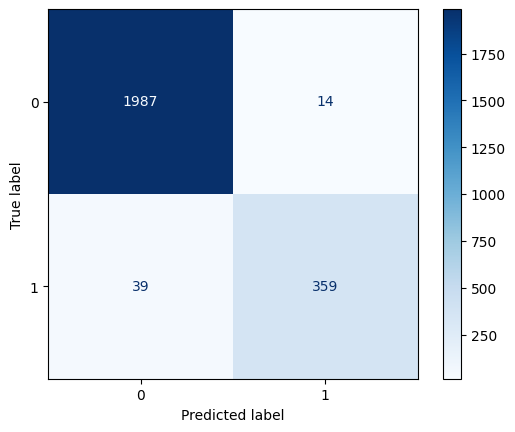

In [337]:
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap="Blues")
plt.show()

In [338]:
with open("model/model.pkl", "wb") as file:
    pickle.dump(model, file)